In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

print("Machine Learning libraries loaded successfully!")

Machine Learning libraries loaded successfully!


In [2]:
customers = pd.read_csv("../data/customers.csv")
loans = pd.read_csv("../data/loans_ml.csv")

print("Corrected ML loan data loaded!")
print("Rows:", loans.shape[0])
print("Columns:", loans.shape[1])

print("Customer data:", customers.shape)
print("Loan data:", loans.shape)

Corrected ML loan data loaded!
Rows: 15000
Columns: 11
Customer data: (10000, 15)
Loan data: (15000, 11)


In [3]:

ml_data = loans.merge(
    customers[
        [
            "Customer_ID",
            "Age",
            "Credit_Score",
            "Annual_Income",
            "Account_Balance",
            "Occupation"
        ]
    ],
    on="Customer_ID",
    how="left"
)

print("ML dataset shape:", ml_data.shape)
print("\nMissing values:")
print(ml_data.isnull().sum())

ML dataset shape: (15000, 16)

Missing values:
Loan_ID             0
Customer_ID         0
Branch_ID           0
Loan_Type           0
Loan_Amount         0
Interest_Rate       0
Loan_Term_Months    0
Loan_Status         0
Application_Date    0
Approval_Date       0
Default_Flag        0
Age                 0
Credit_Score        0
Annual_Income       0
Account_Balance     0
Occupation          0
dtype: int64


In [4]:
ml_data.isnull().sum()

Loan_ID             0
Customer_ID         0
Branch_ID           0
Loan_Type           0
Loan_Amount         0
Interest_Rate       0
Loan_Term_Months    0
Loan_Status         0
Application_Date    0
Approval_Date       0
Default_Flag        0
Age                 0
Credit_Score        0
Annual_Income       0
Account_Balance     0
Occupation          0
dtype: int64

In [5]:
print("Default distribution:")
print(ml_data["Default_Flag"].value_counts())

print("\nDefault percentage:")
print(
    (ml_data["Default_Flag"].value_counts(normalize=True) * 100).round(2)
)

Default distribution:
Default_Flag
0    11541
1     3459
Name: count, dtype: int64

Default percentage:
Default_Flag
0    76.94
1    23.06
Name: proportion, dtype: float64


In [6]:
features = [
    "Age",
    "Credit_Score",
    "Annual_Income",
    "Account_Balance",
    "Loan_Amount",
    "Interest_Rate",
    "Loan_Term_Months"
]

X = ml_data[features]
y = ml_data["Default_Flag"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (15000, 7)
y shape: (15000,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (12000, 7)
Testing features: (3000, 7)
Training target: (12000,)
Testing target: (3000,)


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed!
Training data shape: (12000, 7)
Testing data shape: (3000, 7)


In [9]:
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [10]:
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Predictions created successfully!")
print("Number of predictions:", len(y_pred_logistic))

Predictions created successfully!
Number of predictions: 3000


In [11]:
accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Logistic Regression Performance
--------------------------------
Accuracy : 0.7757
Precision: 0.6557
Recall   : 0.0578
F1 Score : 0.1062


In [12]:
print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

           0       0.78      0.99      0.87      2308
           1       0.66      0.06      0.11       692

    accuracy                           0.78      3000
   macro avg       0.72      0.52      0.49      3000
weighted avg       0.75      0.78      0.70      3000



In [13]:
cm = confusion_matrix(y_test, y_pred_logistic)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2287   21]
 [ 652   40]]


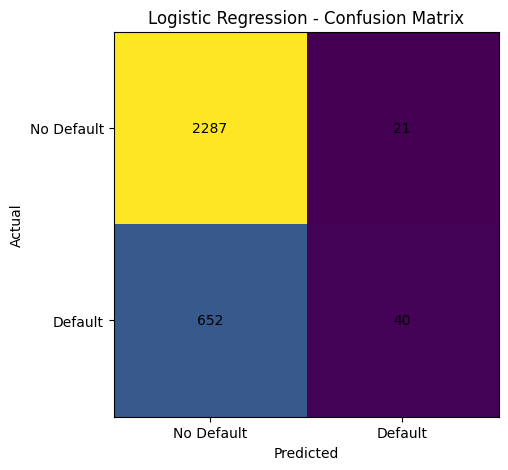

In [14]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No Default", "Default"])
plt.yticks([0, 1], ["No Default", "Default"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [15]:
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    y_prob_logistic
)

print("Logistic Regression ROC-AUC:", round(roc_auc, 4))

Logistic Regression ROC-AUC: 0.7001


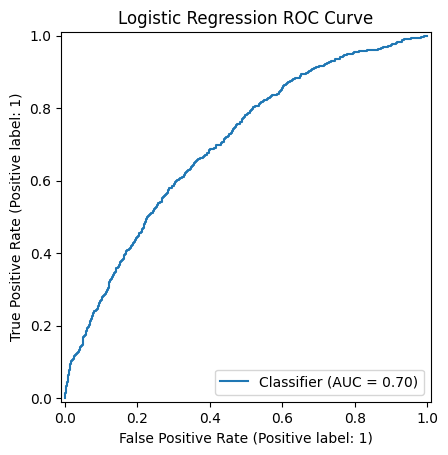

In [16]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_logistic
)

plt.title("Logistic Regression ROC Curve")
plt.show()

In [18]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

random_forest.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!") 

Random Forest model trained successfully!


In [19]:
y_pred_rf = random_forest.predict(X_test)

print("Random Forest predictions created!")
print("Number of predictions:", len(y_pred_rf))

Random Forest predictions created!
Number of predictions: 3000


In [20]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))


Random Forest Performance
--------------------------
Accuracy : 0.767
Precision: 0.472
Recall   : 0.0853
F1 Score : 0.1444


In [21]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.78      0.97      0.87      2308
           1       0.47      0.09      0.14       692

    accuracy                           0.77      3000
   macro avg       0.63      0.53      0.50      3000
weighted avg       0.71      0.77      0.70      3000



In [22]:
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(
    y_test,
    y_prob_rf
)

print("Random Forest ROC-AUC:", round(roc_auc_rf, 4))

Random Forest ROC-AUC: 0.6894


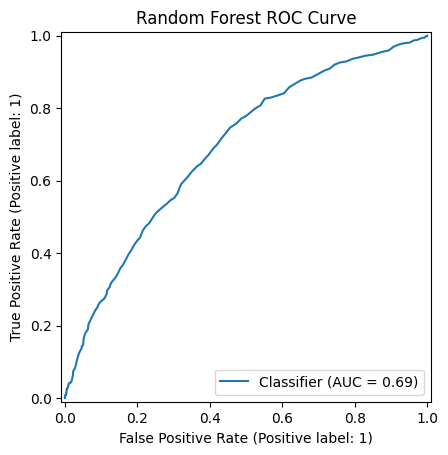

In [23]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf
)

plt.title("Random Forest ROC Curve")
plt.show()


In [24]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        accuracy_rf
    ],
    "Precision": [
        precision,
        precision_rf
    ],
    "Recall": [
        recall,
        recall_rf
    ],
    "F1 Score": [
        f1,
        f1_rf
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_rf
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.775667,0.655738,0.057803,0.106242,0.700135
1,Random Forest,0.767000,0.472000,0.085260,0.144431,0.689435


In [25]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,Annual_Income,0.183320
1,Credit_Score,0.175458
4,Loan_Amount,0.167436
5,Interest_Rate,0.154556
3,Account_Balance,0.138274
0,Age,0.108260
6,Loan_Term_Months,0.072698


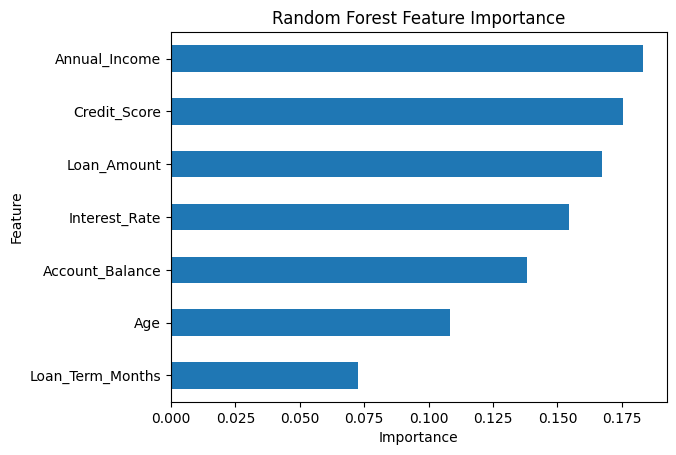

In [26]:
feature_importance.sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    title="Random Forest Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [27]:
comparison.to_csv(
    "../data/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [28]:
feature_importance.to_csv(
    "../data/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


# Machine Learning Summary

## Objective
Predict whether a banking loan is likely to default using customer and loan characteristics.

## Features Used
- Age
- Credit Score
- Annual Income
- Account Balance
- Loan Amount
- Interest Rate
- Loan Term

## Models Used
1. Logistic Regression
2. Random Forest

## Evaluation Metrics
The models were evaluated using:
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix

## Business Purpose
The model can help identify loans with higher estimated default risk and support risk-focused analysis.

## Important Note
The dataset is synthetically generated for portfolio and learning purposes. Model results should not be interpreted as predictions of real-world banking customers.